# Série 5

## Exercice 1
Vous allez devoir implémenter un algorithme pour trouver la meilleure combinaison dans la multiplication de n matrices  M<sub>1</sub>, ..., M<sub>n</sub> dont le vecteur D=(d<sub>0</sub>,d<sub>1</sub>,...d<sub>n</sub>) fournit les dimenstion de la matrice M<sub>i</sub> = d<sub>i-1</sub> × d<sub>i</sub>

Vous devez:
* générer un nombre entier aléatoire *random* plus grand ou égal à 3 (le nombre de matrices)  
* générer un vecteur de *random*+1 dimensions aléatoires comprises entre, 2 et 19: D<sub>*random*</sub>
* générer random matrices à valeurs entières M<sub>i</sub> de dimension d<sub>i-1</sub> × d<sub>i</sub> pour i = 1, ..., *random*
* programmer l'algorithme de recherche de la meilleures combinaison
* trouver la meilleure combinaison et multiplier leurs matrices selon la meilleure combinaison
* tester éventuellement avec des combinaisons aléatoires de leur suite de matrices (pour ce dernier exercice, il faut implémenter un compteur de multiplications scalaires dans la fonction de multiplication matricielle)

In [1]:
import sys

class MatrixMult:
    nmbre_matr = 1
    dimensions = []
    MAX_VALUE = sys.maxsize

    def __init__(self, dimensions, nmbre_matr):
        self.nmbre_matr = nmbre_matr
        self.dimensions = dimensions
        self.best_pivot = [[0 for i in range(nmbre_matr+1)] for j in range(nmbre_matr+1)]
        self.pivots_in_postorder = []

    def best_n_mult(self,high):
        print(high)
        best_value = [[0 for i in range(high+1)] for j in range(high+1)]
        h=2
        while h<=high:
            l=h-2
            while l>=0:
                min_n_mult = self.MAX_VALUE+1
                i=l+1
                while i<=h-1:
                    n_mult = self.dimensions[l]*self.dimensions[i]*self.dimensions[h] + best_value[l][i] + best_value[i][h]
                    if min_n_mult > n_mult:
                        min_n_mult = n_mult
                        self.best_pivot[l][h] = i
                    i+=1
                best_value[l][h] = min_n_mult
                print(l,h,best_value[l][h])
                l-=1
            h+=1
        print(best_value)
        return best_value[0][high]

    def write_pivots_in_postorder(self,l,h):
        if ( l+1 < h ):
            b = self.best_pivot[l][h]
            self.write_pivots_in_postorder(l, b)
            self.write_pivots_in_postorder(b, h)
            self.pivots_in_postorder.append(b)
            print(b)

import random

n = random.randint(3, 15)
nmbre_matr = n #nombre de matrice généré aléatoirement
dimensions = [random.randint(2, 19) for i in range(n+1)]

matrices = []
for i in range(n):
  x = dimensions[i] #lignes
  y = dimensions[i+1] #colonnes
  matrix = [[random.randint(1, 20) for i in range(y)] for j in range(x)]
  matrices.append(matrix)

def matmul(A, B, dim_A, dim_B):
  # C = p x q x r
  p = dim_A[0]
  qA = dim_A[1]
  qB = dim_B[0]
  r = dim_B[1]

  if qA != qB:
    raise ValueError("Dimensions incompatibles")
  else:
    C = [[0 for m in range(r)] for n in range(p)]
    compteur = 0
    for i in range(p):
      for j in range(r):
        for k in range(qA):
          C[i][j] += A[i][k] * B[k][j]
          compteur += 1
    return C, compteur, (p, r) # Return the resulting matrix, counter, and dimensions

def do_operation(matrices, pivots, l, h, dimensions):
  if l + 1 == h:
    return matrices[l], (dimensions[l], dimensions[h]), 0 # Return the matrix and its dimensions

  else:
    b = pivots[l][h]
    left_matrix, left_dim, left_count = do_operation(matrices, pivots, l, b, dimensions)
    right_matrix, right_dim, right_count = do_operation(matrices, pivots, b, h, dimensions)
    prod_matrix, prod_count, prod_dim = matmul(left_matrix, right_matrix, left_dim, right_dim)
    total_count = left_count + right_count + prod_count
    return prod_matrix, prod_dim, total_count

In [2]:
dimensions = [3, 3, 3, 3, 2, 2]
nmbre_matr = 5
print("Dimensions vector:")
print(nmbre_matr, dimensions)
print()

print("\"Random\" matrices: ")

matrices = [[[10,6,19],[7,16,13],[8,12,18]],[[13,20,14],[6,8,5],[14,3,9]],[[15,18,1],[7,7,6],[6,20,17]],[[4,1],[14,14],[15,9]],[[6,10],[17,17]]]
print(matrices)
print()
a = MatrixMult(dimensions, nmbre_matr)
print("best_n_mult: ")
a.best_n_mult(nmbre_matr)
print()
print("write_pivots_in_postorder: ")
a.write_pivots_in_postorder( 0, nmbre_matr)
print()

# Fonction qui multiplie les matrices dans le bon ordre.
pivots = a.best_pivot
final_matrix, final_dim, total_count = do_operation(matrices, pivots, 0, nmbre_matr, dimensions)

print("Final matrix:")
print(final_matrix)
assert final_matrix == [[7782820,9373872],[6874034,8281554],[7700480,9274968]]

Dimensions vector:
5 [3, 3, 3, 3, 2, 2]

"Random" matrices: 
[[[10, 6, 19], [7, 16, 13], [8, 12, 18]], [[13, 20, 14], [6, 8, 5], [14, 3, 9]], [[15, 18, 1], [7, 7, 6], [6, 20, 17]], [[4, 1], [14, 14], [15, 9]], [[6, 10], [17, 17]]]

best_n_mult: 
5
0 2 27
1 3 27
0 3 54
2 4 18
1 4 36
0 4 54
3 5 12
2 5 30
1 5 48
0 5 66
[[0, 0, 27, 54, 54, 66], [0, 0, 0, 27, 36, 48], [0, 0, 0, 0, 18, 30], [0, 0, 0, 0, 0, 12], [0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0]]

write_pivots_in_postorder: 
4
3
2
1

Final matrix:
[[7782820, 9373872], [6874034, 8281554], [7700480, 9274968]]


### Explications

Ce code fait une classe MatrixMult qui va s'occuper d'optimiser les multiplications matricielle en trouvant le meilleur parenthésage optimal qui minimise le nombre total de multiplications scalaires nécessaires.
La constante sys.maxsize va etre utilisé pour fournir la plus grande valeur pour pouvoir la comparer par la suite.
La methode best_n_mult calcule le cout minimal et remplit la table des meilleurs pivots(best_pivot). La méthode write_pivots_in_postorder affiche les pivots sans reconstruite la chaine en parenthèse.
Pour finir la méthode do_operation exécute enfin les multiplications selons les résultats obtenus avec best_pivot et calcule le nombre total d'opérations.


## Exercice 2 - La revanche du puits magique

Lors du cours de récurrence, vous aviez certainement effectué une recherche exhaustive en créant un arbre des possibilités et en prenant le minimum parmi les feuilles. Cet algorithme, tout à fait correct pour une première approche, avait cependant une complexité temporelle de $O(3^L)$. Nous allons utiliser la programmation dynamique pour améliorer cela.

Prenons une liste $u$ de termes $u_{i}$ correspondant au plus petit nombre de pièces pour obtenir $i$ fleurs. Que valent $u_0$ et $u_1$ ?

On rappel les règles qui sont régis par le puit :
On a plus de pièces que le puit a de nénuphare et on cherche à optimiser l'échange pièce nénuphare (vider le puit avec le moins de pièces possible)

On sait que si on jette 1 pièce le puit nous donne un nénuphare

4 pièces le puits garde en mémoire (une dette) le nombre de nénuphares qu'on a récupérer

2 pièces le puits donne autant de nénuphare que "la dette" qu'il a en mémoire

u0 = plus petit nombre de pièces à jetter pour avoir 0 fleur alors ici on est dans le cas trivial ou s'il l'on veut rien on va rien donner donc 0 pièces et u0 = 0

u1 = 1 trivial on jette une pièce on obtient une fleur

Pour $i>1$, il existe deux façons possibles d'obtenir $i$ fleurs - soit nous collectons d'abord $i-1$ fleurs, puis utilisons une opération d'une pièce pour obtenir un autre fleurs, soit la dernière opération doit avoir été une opération de deux pièces. Cela signifie que nous avions demandé au puits de se souvenir de l'état de notre panier à $k$ fleurs (où $k$ est un diviseur de $i$) et ensuite appliqué $\frac{i}{k}-1$ opérations de deux pièces.

Avec une expression plus formelle, nous aurions une formule similaire à cela (formule $(1)$) :

$$u_{i}=\min \left(□, \min _{k \mid i}\left\{u_{k}+4+2\left(\frac{i}{k}-1\right)\right\}\right).$$

Que faudrait-il mettre à la place du "□" ?

On cherche à déterminer ui correspondant au nombre minimal pour obtenir i fleurs
On nous donne deux facons d'obtenir i fleurs, donc on cherche d'abord à minimiser le chemin pour obtenir i fleurs ou on obtient d'abord k fleurs puis on fait des opération à 2 pièces...
et donc à la place du "□" on peut donc déduire que ça serait l'autre méthode on cherche à avoir i-1 fleurs dans un premier temps puis on complète par une pièce pour avoir i fleurs ce qui se traduit par u(i-1) + 1

Au lieu d'itérer sur les diviseurs de $i$ comme la formule nous le permettrait, nous allons procéder comme suit :

Au début, nous pouvons dire que toutes les valeurs de la suite, les $u_i$ (sauf $u_0$ et $u_1$), sont égales à l'infini. Maintenant, parcourons toutes les valeurs de $i$ de $2$ à $N$ ($N$ étant un entier que vous choisirez à votre convenance...). Une des possibilités est d'utiliser une pièce et ainsi passer de $i-1$ fleurs à $i$ fleurs, donc nous pouvons dire que $u_i\leftarrow \min(u_i, u_{i-1}+1)$.

À présent, lorsque nous avons déjà $i$ fleurs, nous pouvons également utiliser quatre pièces pour mémoriser l'état de notre panier, puis obtenir plus tard $j \cdot i$ fleurs du puits. Nous devrions donc mettre à jour $u_i$ pour tous les multiples de $i$ avec la formule $(2)$:

$$u_{j \cdot i} = \min(u_{j \cdot i}, u_i + 4 + 2 \cdot (j - 1)), i < j \cdot i ≤ N$$

Implémentez ce travail dans la fonction suivante :

In [3]:
import math

def min_well_coin(L):
    U = [math.inf] * (L + 1)
    U[0] = 0
    U[1] = 1

    # For each i...
    for i in range(2, L + 1):
        # u_i can be obtained from u_i-1
        U[i] = min(U[i],U[i-1] + 1) #rempli naivement le panier
        for j in range(2, (L // i) + 1): #multiples de i; 2i, 3i
              U[i*j] = min(U[i*j], U[i] + 4 + 2*(j - 1))
            #for k in range(1, i):
            #division_condition = (i % k == 0) #k est multiple de i
            #if division_condition:
             #   U[i] = min(U[i], U[k] + 4 + 2 * ((i // k) - 1))

    # Return the correct term from the U sequence
    return U[L]

In [4]:
assert min_well_coin(12) == 12
assert min_well_coin(13) == 13
assert min_well_coin(15) == 13
assert min_well_coin(16) == 14
assert min_well_coin(17) == 15
assert min_well_coin(18) == 14
assert min_well_coin(19) == 15
assert min_well_coin(21) == 15
assert min_well_coin(22) == 16
assert min_well_coin(23) == 17
assert min_well_coin(93) == 27
assert min_well_coin(94) == 28
assert min_well_coin(96) == 26
assert min_well_coin(97) == 27

Que pouvait-on choisir pour $N$ en fin de compte ?

Explication du code : On définit un tableau U[i] qui caractèrise le nombre minimal de pièces pour obtenir i fleurs, On remplie ce tableau de 0 à L
chaque U[j] est obtenu à partir de valeurs déjà calculé pour un certain i< j,
On a deux moyens d'obtenir : cas naif U[i] = min(U[i],U[i-1] + 1)

ou une fois i fleurs obtenus
ou pour obtenir un multiple de i disons k = k*j alors on peut mémoriser avec 4 pièces puis répéter l'opération j fois afin d'obtenir i + i + i... j fois --> min(U[i*j], U[i] + 4 + 2*(j - 1))
ainsi on propage les multiples de j*i <= L ainsi on optimise le tableau au fur et à mesure

On boucle que jusqu'à (L+1) comme N est une borne supérieur arbitraire on peut prendre N=L le nombre de fleurs qu'on veut au final.

Affichez sur un graphe les valeurs de la fonction pour $L$ allant de $0$ à $1000$. Quel est l'aspect du graphe ?

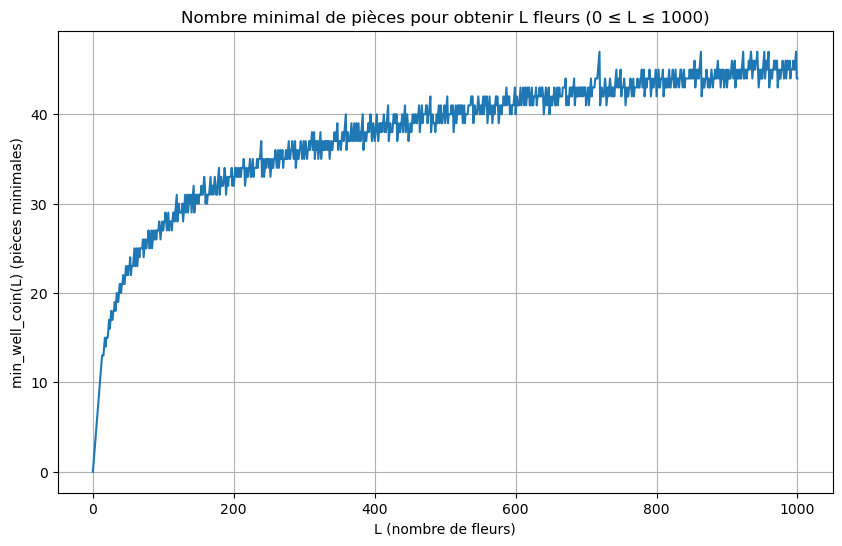

In [5]:
import matplotlib.pyplot as plt

vals = [0, 1] + [min_well_coin(L) for L in range(2, 1001)]  # on met 0 et 1 à la main

plt.figure(figsize=(10,6))
plt.plot(range(1001), vals, linestyle='-')
plt.xlabel("L (nombre de fleurs)")
plt.ylabel("min_well_coin(L) (pièces minimales)")
plt.title("Nombre minimal de pièces pour obtenir L fleurs (0 ≤ L ≤ 1000)")
plt.grid(True)
plt.show()

### Explications

On peut voir que l'on obtient une fonction logarithmique qui croit nettement moi fort à mesure que le nombre de fleurs à obtenir augmente. Ce qui est nettement mieux que le résultat qu'on obtenait dans le série précédante ou on explorait chaque feuille de l'arbre de possibilité

Quelle est la complexité temporelle de cet algorithme ? Que pouvez-vous en dire au regard de la recherche exhaustive codée plus tôt en lab ?

### Explications

on a la boucle interne un range de 2 à L/i + 1 ce qui donne L/i-1 itérations ensuite on boucle de 2 à L donc on a : (on compte pas U[0] et U[1] qui sont insignifiants)   
∑L​((L/i)​−1) <= ∑(L​/i) = L∑(i​/i) de à 2 à L ce L⋅HL​∼LlogL. avec HL la somme harmonique qui correspond plus au moins à LogL opérations (on peut voir que le résultat est cohérant avec le graphe)
